# code_225 · Reconstruct the decision that actually occurred

**Book:** section 42.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_42_GUIDE.md), [execution evidence](../CHAPTER_42_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_225).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Monitoring separates observable inputs, historical predictions, delayed outcome maturity, selection mechanisms, operational versions and authority to update. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8025;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8025


## Replay an incident using the original snapshot and all four versions
 Fit a logistic finding model on1,200 generated source rows with load in kN and age scaled to decades. A historical feature-v1 defect divides every load by1,000 regardless of its unit. A retained request with load8kN and age30years therefore receives an incorrectly small load and misses a generated finding at threshold0.5. Store canonical raw JSON bytes, a snapshot digest, data/schema version, feature function version, coefficient/intercept model state and threshold-policy version. Recompute the exact original probability/decision from retained state. A later corrected feature-v2 handles N versus kN explicitly; replaying history with that latest feature would produce a different prediction and conceal the original incident. The finding is an authored simulator fixture, not evidence about a real structure.


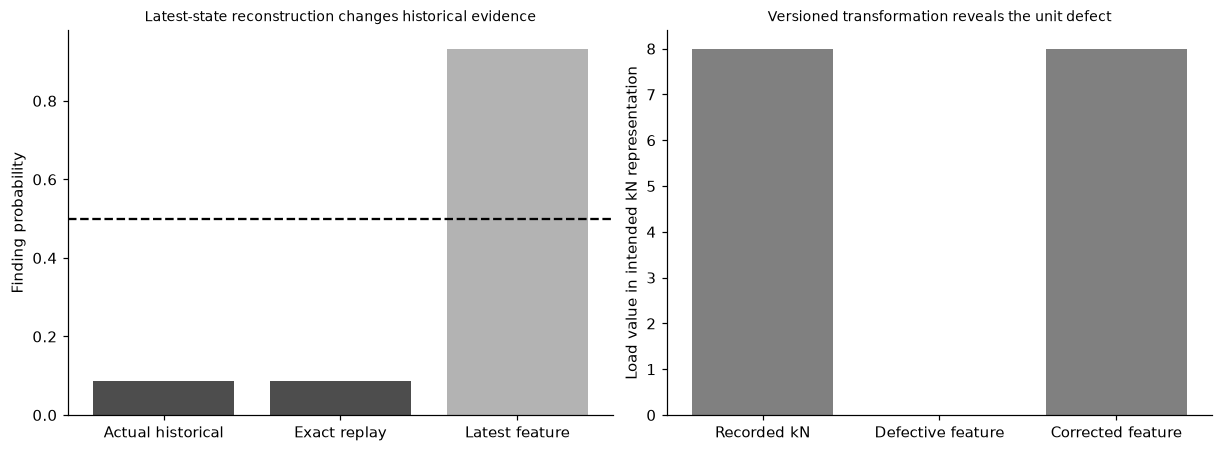

In [2]:
import hashlib
from sklearn.linear_model import LogisticRegression
xs=np.c_[rng.uniform(0,10,1200),rng.uniform(0,8,1200)];ys=rng.binomial(1,expit(-3+.7*xs[:,0]+.15*xs[:,1]));model=LogisticRegression(C=1).fit(xs,ys);state={'coef':model.coef_[0].tolist(),'intercept':float(model.intercept_[0]),'model_version':'risk-v1'};raw={'asset':'fictional-17','load':8.,'load_unit':'kN','age_years':30.,'prediction_day':17};raw_bytes=json.dumps(raw,sort_keys=True,separators=(',',':')).encode()
def features(record,version):
    if version=='feature-v1':return np.array([record['load']/1000,record['age_years']/10])
    if record['load_unit'] not in ['N','kN']:raise ValueError('Invalid load unit')
    return np.array([record['load']/(1000 if record['load_unit']=='N' else 1),record['age_years']/10])
def probability(record,feature_version):return float(expit(features(record,feature_version)@np.array(state['coef'])+state['intercept']))
historical=probability(raw,'feature-v1');corrected=probability(raw,'feature-v2');record={'snapshot_sha256':hashlib.sha256(raw_bytes).hexdigest(),'data_version':'snapshot17/schema1','feature_version':'feature-v1','model_version':'risk-v1','decision_version':'policy-v1/threshold0.5','threshold':.5,'probability':historical,'alarm':historical>=.5,'generated_observed_finding':1};replayed=probability(json.loads(raw_bytes),record['feature_version']);assert replayed==record['probability'] and (replayed>=record['threshold'])==record['alarm'];assert historical<.5 and corrected>.5;assert hashlib.sha256(raw_bytes).hexdigest()==record['snapshot_sha256'];RESULTS.update(source_rows=1200,historical_record=record,corrected_latest_feature_probability=corrected,historical_exact_replay=True,latest_feature_would_conceal_missed_alarm=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['Actual historical','Exact replay','Latest feature'],[historical,replayed,corrected],color=['.3','.3','.7']);axes[0].axhline(.5,color='black',linestyle='--');axes[0].set(ylabel='Finding probability',title='Latest-state reconstruction changes historical evidence');axes[1].bar(['Recorded kN','Defective feature','Corrected feature'],[8.,features(raw,'feature-v1')[0],features(raw,'feature-v2')[0]],color='.5');axes[1].set(ylabel='Load value in intended kN representation',title='Versioned transformation reveals the unit defect');plt.show()


## Repair the interface, preserve evidence and retire an unsupported task
 Validate feature-v2 by requiring equivalent8kN/8,000N requests to produce identical probabilities and rejecting an unknown unit. Keep the old snapshot/model/policy immutable. A fictional incident owner suspends the affected feature route; a distinct reviewer records a local verified-repair state after tests. A later task change asks the annual inspection-priority model for immediate structural clearance, which its event and evidence do not support. Retire that use route and reject subsequent requests rather than rename the score. Owner strings and state transitions are policy fixtures, not real human approval. Snapshot hashes detect changes against a retained expected digest, not trusted identity or tamperproof storage.


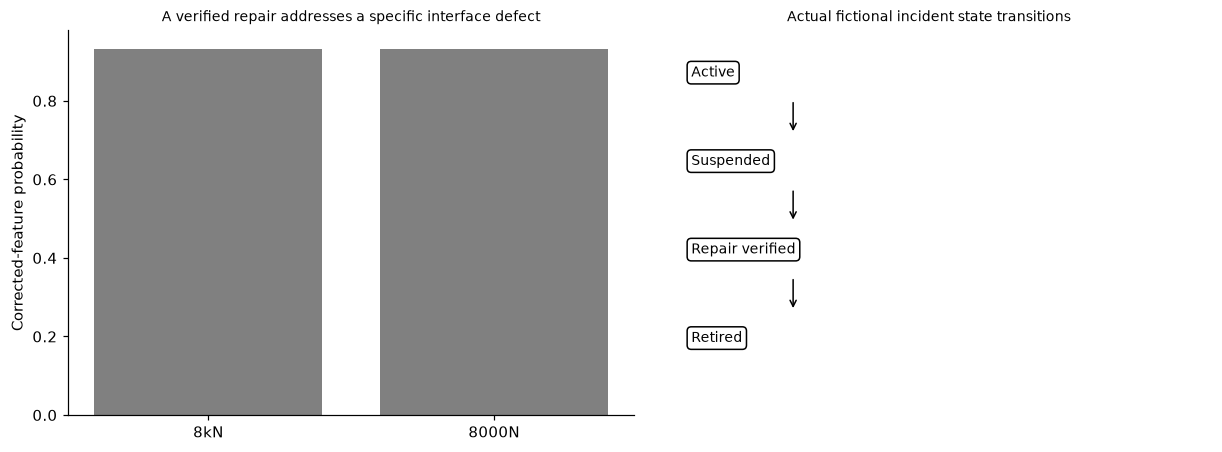

In [3]:
equivalent={**raw,'load':8000.,'load_unit':'N'};assert probability(raw,'feature-v2')==probability(equivalent,'feature-v2');rejected=False
try:probability({**raw,'load_unit':'unknown'},'feature-v2')
except ValueError:rejected=True
assert rejected;events=[];lifecycle={'state':'active','permitted_use':'annual-review-priority'}
def transition(owner,target,reason):
    allowed={('active','suspended'):'incident_owner',('suspended','repair_verified'):'reviewer',('repair_verified','retired'):'decision_owner'}
    if allowed.get((lifecycle['state'],target))!=owner:raise PermissionError('Invalid owner or transition')
    events.append({'owner':owner,'from':lifecycle['state'],'to':target,'reason':reason});lifecycle['state']=target
transition('incident_owner','suspended','feature-v1 unit defect; retain snapshot17');transition('reviewer','repair_verified','feature-v2 equivalent-unit and rejection fixtures pass');transition('decision_owner','retired','requested immediate structural clearance exceeds annual finding target')
def request(use):
    if lifecycle['state']=='retired' or use!=lifecycle['permitted_use']:return {'status':'rejected','probability':None}
    return {'status':'review_only','probability':corrected}
denied=request('immediate-structural-clearance');assert denied['status']=='rejected' and denied['probability'] is None;assert hashlib.sha256(raw_bytes).hexdigest()==record['snapshot_sha256'];RESULTS.update(equivalent_units_repair_passed=True,unknown_unit_rejected=True,incident_events=events,retired_state=lifecycle['state'],unsupported_task_request=denied,original_snapshot_unchanged=True,real_human_approval_or_structural_clearance=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['8kN','8000N'],[probability(raw,'feature-v2'),probability(equivalent,'feature-v2')],color='.5');axes[0].set(ylabel='Corrected-feature probability',title='A verified repair addresses a specific interface defect');axes[1].axis('off');axes[1].set(xlim=(0,5),ylim=(0,5));stages=['Active','Suspended','Repair verified','Retired']
for j,name in enumerate(stages):
    axes[1].text(.4,4.4-j*1.15,name,fontsize=9,bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'})
    if j<3:axes[1].annotate('',xy=(1.3,3.65-j*1.15),xytext=(1.3,4.1-j*1.15),arrowprops={'arrowstyle':'->'})
axes[1].set_title('Actual fictional incident state transitions');plt.show()


In [4]:
summary={'example_id':'code_225','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual canonical raw snapshot data feature model and decision version binding', 'replay of historical unit-conversion defect and threshold decision with exact retained parameters', 'latest-version reconstruction counterexample and repaired-schema validation', 'fictional incident ownership suspension and task-based retirement with rejected future use'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual canonical raw snapshot data feature model and decision version binding", "replay of historical unit-conversion defect and threshold decision with exact retained parameters", "latest-version reconstruction counterexample and repaired-schema validation", "fictional incident ownership suspension and task-based retirement with rejected future use"], "elapsed_seconds": 0.269, "example_id": "code_225", "hardware": "Darwin arm64 CPU", "results": {"corrected_latest_feature_probability": 0.9329164782400007, "equivalent_units_repair_passed": true, "historical_exact_replay": true, "historical_record": {"alarm": false, "data_version": "snapshot17/schema1", "decision_version": "policy-v1/threshold0.5", "feature_version": "feature-v1", "generated_observed_finding": 1, "model_version": "risk-v1", "probability": 0.0870942978348489, "snapshot_sha256": "f05e55a364671948b032b5cd03110df603b40416720ac1459185cb5c90049d9f", "threshold": 0.5}, "inciden